# 04.2 KNN: búsqueda de hiperparámetros (experimento 2)

- Entrada: `data/processed/dev_features.csv` (salida del notebook 03)
- Salida: `best_params/`, `trials/` y `figures/` de este modelo (cada archivo está explicado en el `README.md` del experimento 1)

Es la misma búsqueda del experimento 1 con las variables del experimento 2: los mejores ajustes dependen de las variables de entrada, así que hay que repetirla. Qué cambia y por qué está explicado en el notebook de modelado del experimento 2.

Instrucciones:

- Misma validación que en el experimento 1: 5 grupos separados por animal, semilla `SEED` y `N_TRIALS` pruebas.
- Nombre de los archivos que se generan: `knn_clf` y `knn_reg`.
- No usar `test`.

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.pipeline import Pipeline

from config import SEED
from features import CAT_LOW, CAT_HIGH, BINARY, NUMERIC, NUMERIC_LOG, add_age_log, build_preprocessor
from tuning import tune

N_TRIALS = 20

data = add_age_log(pd.read_csv("../../data/processed/dev_features.csv"))
groups = data["animal_id_intake"]

/Users/klorenzoe/Documents/Personal/MUCSI/ML/mucsi-ml-animal-shelter-project/.venv/lib/python3.15/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Inputs

Las mismas variables que el SVM del experimento 2. Frente al experimento 1 se agregan raza, color y ciudad (`CAT_HIGH`) y, en regresión, la edad se usa en logaritmo (`age_log`) en lugar de `age_days`.

In [2]:
FEATURES_EXP2_CLF = CAT_LOW + CAT_HIGH + BINARY + NUMERIC
FEATURES_EXP2_REG = CAT_LOW + CAT_HIGH + BINARY + [c for c in NUMERIC if c != "age_days"] + NUMERIC_LOG

print("El experimento 2 usa estas variables:")
print("Clasificación:", FEATURES_EXP2_CLF)
print("Regresión:", FEATURES_EXP2_REG)

# Clasificación: todas las filas
y_clf = data["y_outcome"]

# Regresión: solo adoptados
adopted = data["y_outcome"] == "Adoption"
y_reg = data.loc[adopted, "y_log_days"]
groups_reg = groups[adopted]

El experimento 2 usa estas variables:
Clasificación: ['animal_type', 'intake_type', 'intake_condition', 'sex', 'weekday', 'season', 'breed_main', 'color_main', 'city', 'is_neutered', 'is_mix', 'is_crossbreed', 'is_bicolor', 'is_tabby', 'has_location_detail', 'is_baby', 'condition_serious', 'age_days', 'prior_stays', 'hour', 'month', 't_months']
Regresión: ['animal_type', 'intake_type', 'intake_condition', 'sex', 'weekday', 'season', 'breed_main', 'color_main', 'city', 'is_neutered', 'is_mix', 'is_crossbreed', 'is_bicolor', 'is_tabby', 'has_location_detail', 'is_baby', 'condition_serious', 'prior_stays', 'hour', 'month', 't_months', 'age_log']


## Qué se ajusta

| Ajuste | Qué hace | Rango probado |
|---|---|---|
| `n_neighbors` | Cuántos animales parecidos se consultan para decidir. Pocos: sigue los detalles y se confunde con casos raros. Muchos: más estable pero más borroso. | 3 a 200 (escala logarítmica) |
| `weights` | `uniform`: todos los vecinos votan igual. `distance`: los más parecidos pesan más. | `uniform` o `distance` |
| `p` | Cómo se mide qué tan parecidos son dos animales. 1 suma las diferencias en cada variable (distancia Manhattan). 2 usa la distancia en línea recta (euclidiana). | 1 o 2 |

Los rangos son los mismos que en el experimento 1. KNN no tiene `class_weight`: no puede dar más peso a las clases pequeñas.

Una evaluación con todos los datos tarda unos 30 segundos en clasificación y 6 en regresión, así que la búsqueda no usa submuestra.

## 1. Clasificación

Objetivo: `y_outcome` (5 clases), con todas las filas. Se elige por macro-F1.

Búsqueda de KNN (clasificación): 20 pruebas con 63,681 filas y 57,564 animales.
Prueba 1/20: resultado 0.497 | mejor hasta ahora 0.497
Prueba 2/20: resultado 0.505 | mejor hasta ahora 0.505
Prueba 3/20: resultado 0.483 | mejor hasta ahora 0.505
Prueba 4/20: resultado 0.513 | mejor hasta ahora 0.513
Prueba 5/20: resultado 0.522 | mejor hasta ahora 0.522
Prueba 6/20: resultado 0.519 | mejor hasta ahora 0.522
Prueba 7/20: resultado 0.480 | mejor hasta ahora 0.522
Prueba 8/20: resultado 0.467 | mejor hasta ahora 0.522
Prueba 9/20: resultado 0.478 | mejor hasta ahora 0.522
Prueba 10/20: resultado 0.523 | mejor hasta ahora 0.523
Prueba 11/20: resultado 0.528 | mejor hasta ahora 0.528
Prueba 12/20: resultado 0.527 | mejor hasta ahora 0.528
Prueba 13/20: resultado 0.527 | mejor hasta ahora 0.528
Prueba 14/20: resultado 0.522 | mejor hasta ahora 0.528
Prueba 15/20: resultado 0.509 | mejor hasta ahora 0.528
Prueba 16/20: resultado 0.526 | mejor hasta ahora 0.528
Prueba 17/20: resultado 0.492 | m

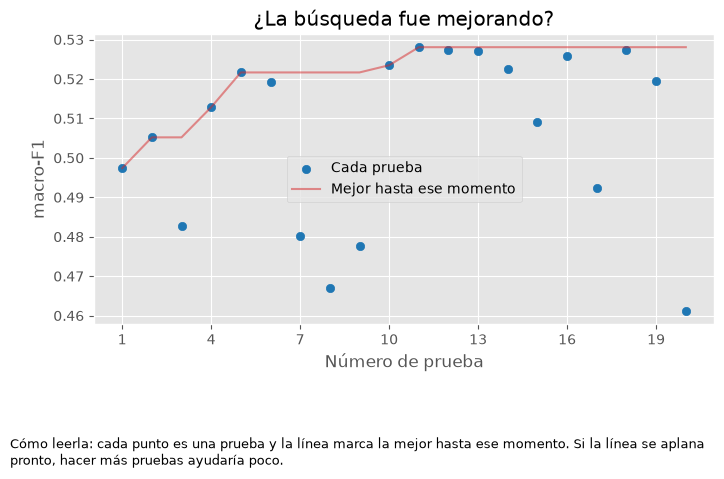

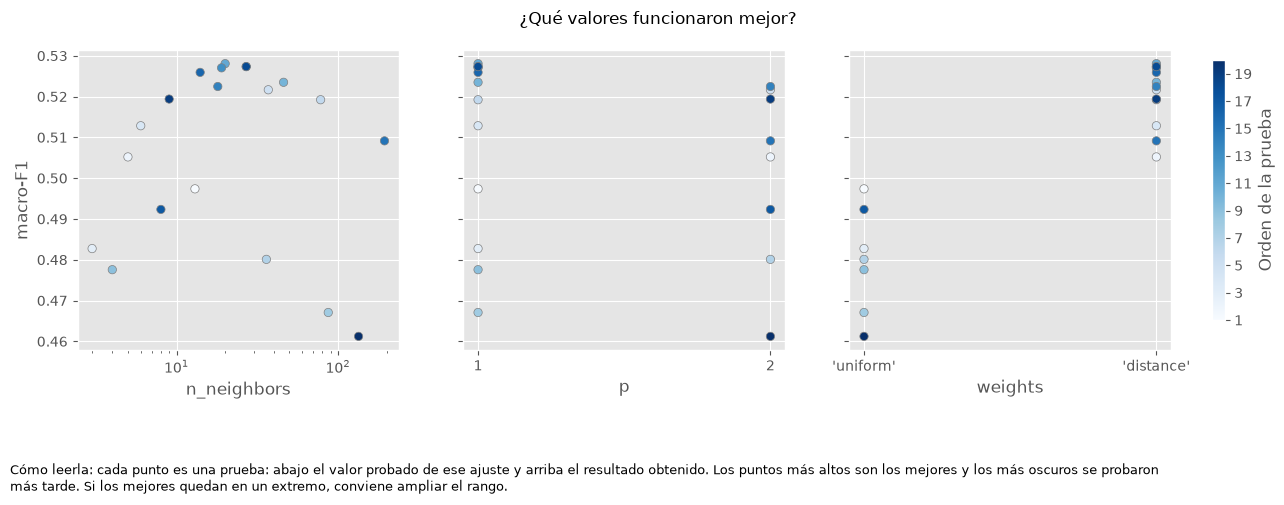

In [3]:
def make_pipe_clf(params):
    return Pipeline([("prep", build_preprocessor(columns=FEATURES_EXP2_CLF)),
                     ("model", KNeighborsClassifier(**params))])

def space(trial):
    return {"n_neighbors": trial.suggest_int("n_neighbors", 3, 200, log=True),
            "weights": trial.suggest_categorical("weights", ["uniform", "distance"]),
            "p": trial.suggest_categorical("p", [1, 2])}

PARAMS_HELP = {"n_neighbors": "Cuántos animales parecidos se consultan para decidir.",
               "weights": "uniform: todos los vecinos votan igual. distance: los más parecidos pesan más.",
               "p": "Cómo se mide la semejanza: 1 suma diferencias (Manhattan), 2 línea recta (euclidiana)."}

study_clf = tune(
    "knn_clf", make_pipe_clf, space, data[FEATURES_EXP2_CLF], y_clf, groups,
    scoring="f1_macro", features=FEATURES_EXP2_CLF, model_label="KNN", task_label="clasificación",
    params_help=PARAMS_HELP, n_trials=N_TRIALS)

## 2. Regresión

Objetivo: `y_log_days`, solo con las filas donde `y_outcome == "Adoption"`. Se elige por R² en log.

Búsqueda de KNN (regresión): 20 pruebas con 27,073 filas y 24,720 animales.
Prueba 1/20: resultado 0.252 | mejor hasta ahora 0.252
Prueba 2/20: resultado 0.216 | mejor hasta ahora 0.252
Prueba 3/20: resultado 0.140 | mejor hasta ahora 0.252
Prueba 4/20: resultado 0.242 | mejor hasta ahora 0.252
Prueba 5/20: resultado 0.283 | mejor hasta ahora 0.283
Prueba 6/20: resultado 0.281 | mejor hasta ahora 0.283
Prueba 7/20: resultado 0.254 | mejor hasta ahora 0.283
Prueba 8/20: resultado 0.240 | mejor hasta ahora 0.283
Prueba 9/20: resultado 0.183 | mejor hasta ahora 0.283
Prueba 10/20: resultado 0.287 | mejor hasta ahora 0.287
Prueba 11/20: resultado 0.288 | mejor hasta ahora 0.288
Prueba 12/20: resultado 0.290 | mejor hasta ahora 0.290
Prueba 13/20: resultado 0.288 | mejor hasta ahora 0.290
Prueba 14/20: resultado 0.281 | mejor hasta ahora 0.290
Prueba 15/20: resultado 0.257 | mejor hasta ahora 0.290
Prueba 16/20: resultado 0.286 | mejor hasta ahora 0.290
Prueba 17/20: resultado 0.231 | mejor

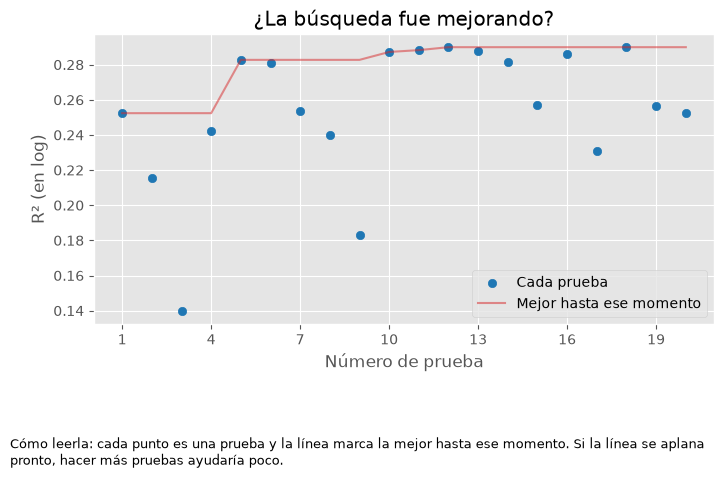

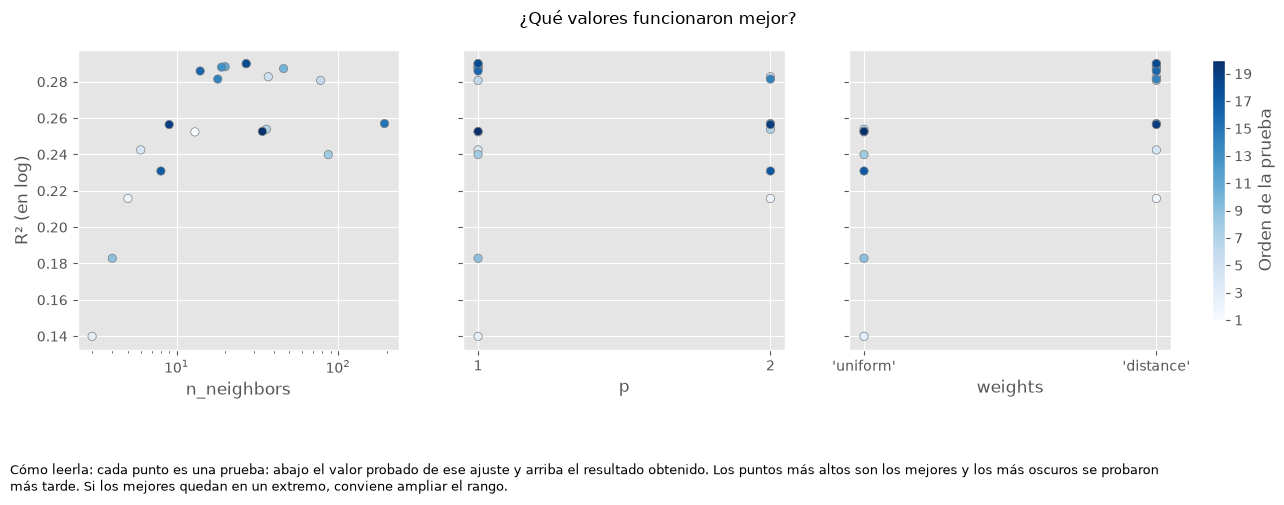

In [4]:
def make_pipe_reg(params):
    return Pipeline([("prep", build_preprocessor(numeric=NUMERIC + NUMERIC_LOG, columns=FEATURES_EXP2_REG)),
                     ("model", KNeighborsRegressor(**params))])

study_reg = tune(
    "knn_reg", make_pipe_reg, space, data.loc[adopted, FEATURES_EXP2_REG], y_reg, groups_reg,
    scoring="r2", features=FEATURES_EXP2_REG, model_label="KNN", task_label="regresión",
    params_help=PARAMS_HELP, n_trials=N_TRIALS)